# 项目二：墨读 App 转化漏斗与用户留存分析

数据是固定随机种子生成的**虚构教学数据**（`data/app/`），不代表任何真实 App 业绩。你将完成全量漏斗、分渠道/分设备定位、留存率、周同期群热力图以及 6 道独立自动检查。

请选择 `Python (da-course)` 内核，从本包 `notebooks/` 目录打开。

> **这是参考答案版**，保留完整示例与解法。代码格下方的输出会在运行后出现。
> 建议先在 `notebooks/` 文件夹里的学生版自己做一遍，卡住了再来这里对照。

In [1]:
import sys
sys.path.insert(0, "..")
from dacheck import check, hint, setup_chinese_font
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. 读取数据与质量体检

In [2]:
users = pd.read_csv("../data/app/app_users.csv", parse_dates=["register_date"], encoding="utf-8-sig")
events = pd.read_csv("../data/app/app_events.csv", parse_dates=["event_time"], encoding="utf-8-sig")
active = pd.read_csv("../data/app/app_active.csv", parse_dates=["active_date"], encoding="utf-8-sig")

assert users["user_id"].is_unique
assert set(events["user_id"]).issubset(set(users["user_id"]))
assert set(active["user_id"]).issubset(set(users["user_id"]))
assert (active["active_date"].max() - users["register_date"].max()).days >= 30
print("质量体检通过：", {"users": users.shape, "events": events.shape, "active": active.shape})

质量体检通过： {'users': (6000, 5), 'events': (15243, 3), 'active': (34166, 2)}


## 2. 全量五步转化漏斗

练习 P-2.1：按 `["app_open", "view_course", "start_trial", "click_pay", "pay_success"]` 顺序计算 `step, users, step_rate, overall_rate`。

In [3]:
STEPS = ["app_open", "view_course", "start_trial", "click_pay", "pay_success"]
cnt = [events.loc[events["event_name"].eq(st), "user_id"].nunique() for st in STEPS]
p2_funnel = pd.DataFrame([
    {"step": st, "users": u, "step_rate": 1.0 if i == 0 else u / cnt[i - 1], "overall_rate": u / cnt[0]}
    for i, (st, u) in enumerate(zip(STEPS, cnt))
])
check("P-2.1", p2_funnel)

True

独立可视化全量漏斗。

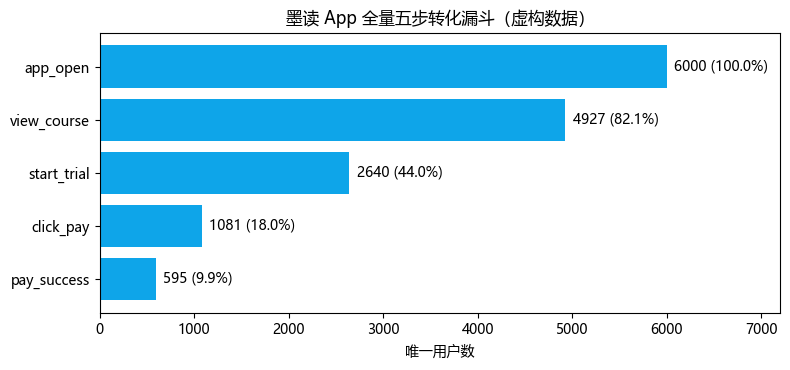

In [4]:
setup_chinese_font()
steps_ref = ["app_open", "view_course", "start_trial", "click_pay", "pay_success"]
cnt_ref = [events.loc[events["event_name"].eq(st), "user_id"].nunique() for st in steps_ref]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(steps_ref[::-1], cnt_ref[::-1], color="#0ea5e9")
ax.set(title="墨读 App 全量五步转化漏斗（虚构数据）", xlabel="唯一用户数", ylabel="")
for i, v in enumerate(cnt_ref[::-1]):
    ax.text(v + 80, i, f"{v} ({v / cnt_ref[0]:.1%})", va="center")
ax.set_xlim(0, 7200)
fig.tight_layout()
plt.show()

## 3. 分渠道与分设备下钻定位瓶颈

练习 P-2.2：按 `channel` 统计 `open_users, trial_users, click_users, pay_users, trial_to_click, overall_pay_rate`，按 `overall_pay_rate` 降序排列。

In [5]:
eu = events.merge(users[["user_id", "channel", "device"]], on="user_id", how="left", validate="many_to_one")
ch_rows = []
for ch, g in eu.groupby("channel"):
    o = g.loc[g["event_name"].eq("app_open"), "user_id"].nunique()
    t = g.loc[g["event_name"].eq("start_trial"), "user_id"].nunique()
    c = g.loc[g["event_name"].eq("click_pay"), "user_id"].nunique()
    p = g.loc[g["event_name"].eq("pay_success"), "user_id"].nunique()
    ch_rows.append({
        "channel": ch, "open_users": o, "trial_users": t, "click_users": c,
        "pay_users": p, "trial_to_click": c / t, "overall_pay_rate": p / o,
    })
p2_channel = pd.DataFrame(ch_rows).sort_values("overall_pay_rate", ascending=False).reset_index(drop=True)
check("P-2.2", p2_channel)

True

练习 P-2.3：按 `device` 统计 `click_users, pay_users, pay_rate = pay_users / click_users`，按 `device` 升序排列。

In [6]:
eu_dev = events.merge(users[["user_id", "device"]], on="user_id", how="left", validate="many_to_one")
dev_rows = []
for dev, g in eu_dev.groupby("device"):
    c = g.loc[g["event_name"].eq("click_pay"), "user_id"].nunique()
    p = g.loc[g["event_name"].eq("pay_success"), "user_id"].nunique()
    dev_rows.append({"device": dev, "click_users": c, "pay_users": p, "pay_rate": p / c})
p2_device = pd.DataFrame(dev_rows).sort_values("device").reset_index(drop=True)
check("P-2.3", p2_device)

True

## 4. 分渠道留存与按周同期群

练习 P-2.4：按 `channel` 统计 `users, d1, d7, d30`（留存率小数），按 `d7` 降序排列。

In [7]:
au = active.merge(users[["user_id", "register_date", "channel"]], on="user_id", how="left", validate="many_to_one")
au["day_diff"] = (au["active_date"] - au["register_date"]).dt.days
p2_ch_ret = users.groupby("channel", as_index=False).agg(users=("user_id", "nunique"))
for d in (1, 7, 30):
    sub = au.loc[au["day_diff"].eq(d)].groupby("channel", as_index=False).agg(**{f"n{d}": ("user_id", "nunique")})
    p2_ch_ret = p2_ch_ret.merge(sub, on="channel", how="left")
    p2_ch_ret[f"d{d}"] = p2_ch_ret[f"n{d}"].fillna(0) / p2_ch_ret["users"]
p2_ch_ret = p2_ch_ret[["channel", "users", "d1", "d7", "d30"]].sort_values("d7", ascending=False).reset_index(drop=True)
check("P-2.4", p2_ch_ret)

True

练习 P-2.5：将 `register_date` 对齐到当周周一 `cohort_week`（`YYYY-MM-DD`），统计每周同期群的 `users` 和 `d7_rate`，按 `cohort_week` 升序排列。

In [8]:
u_w = users.copy()
u_w["cohort_week"] = (u_w["register_date"] - pd.to_timedelta(u_w["register_date"].dt.day_of_week, unit="D")).dt.strftime("%Y-%m-%d")
au_w = active.merge(u_w[["user_id", "register_date", "cohort_week"]], on="user_id", how="left", validate="many_to_one")
au_w["day_diff"] = (au_w["active_date"] - au_w["register_date"]).dt.days
base_w = u_w.groupby("cohort_week", as_index=False).agg(users=("user_id", "nunique"))
d7_w = au_w.loc[au_w["day_diff"].eq(7)].groupby("cohort_week", as_index=False).agg(n7=("user_id", "nunique"))
p2_weekly = base_w.merge(d7_w, on="cohort_week", how="left")
p2_weekly["d7_rate"] = p2_weekly["n7"].fillna(0) / p2_weekly["users"]
p2_weekly = p2_weekly[["cohort_week", "users", "d7_rate"]].sort_values("cohort_week").reset_index(drop=True)
check("P-2.5", p2_weekly)

True

绘制周同期群留存热力图（独立示例，看 D1/D3/D7/D14/D30）。

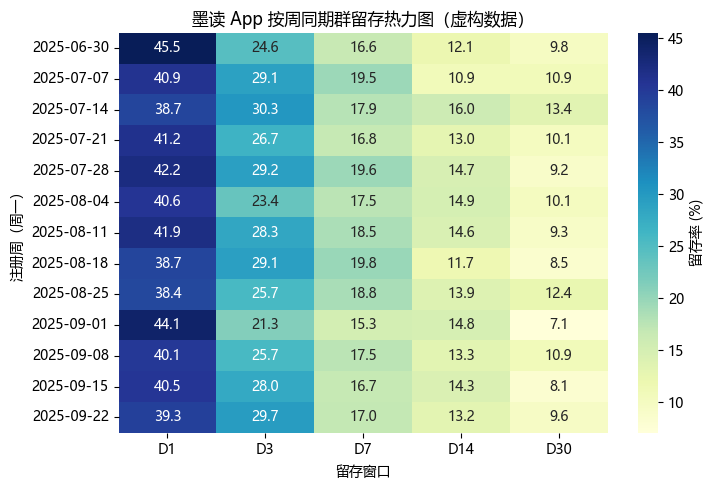

In [9]:
u_hm = users.copy()
u_hm["cohort_week"] = (u_hm["register_date"] - pd.to_timedelta(u_hm["register_date"].dt.day_of_week, unit="D")).dt.strftime("%Y-%m-%d")
au_hm = active.merge(u_hm[["user_id", "register_date", "cohort_week"]], on="user_id", how="left")
au_hm["day_diff"] = (au_hm["active_date"] - au_hm["register_date"]).dt.days
base_hm = u_hm.groupby("cohort_week")["user_id"].nunique()
mat = pd.DataFrame({
    f"D{d}": au_hm.loc[au_hm["day_diff"].eq(d)].groupby("cohort_week")["user_id"].nunique() / base_hm
    for d in [1, 3, 7, 14, 30]
}).fillna(0)
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.heatmap(mat * 100, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "留存率 (%)"})
ax.set(title="墨读 App 按周同期群留存热力图（虚构数据）", xlabel="留存窗口", ylabel="注册周（周一）")
fig.tight_layout()
plt.show()

## 5. 项目二核心指标卡

练习 P-2.6：汇总 6 键指标卡字典：`total_users, overall_pay_rate, best_channel, worst_channel, ios_pay_step_rate, android_pay_step_rate`。

In [10]:
eu_all = events.merge(users[["user_id", "channel", "device"]], on="user_id", how="left")
ch_pay = {
    ch: g.loc[g["event_name"].eq("pay_success"), "user_id"].nunique()
        / g.loc[g["event_name"].eq("app_open"), "user_id"].nunique()
    for ch, g in eu_all.groupby("channel")
}
dev_pay = {
    dev: g.loc[g["event_name"].eq("pay_success"), "user_id"].nunique()
         / g.loc[g["event_name"].eq("click_pay"), "user_id"].nunique()
    for dev, g in eu_all.groupby("device")
}
p2_kpi = {
    "total_users": len(users),
    "overall_pay_rate": events.loc[events["event_name"].eq("pay_success"), "user_id"].nunique() / len(users),
    "best_channel": max(ch_pay, key=ch_pay.get),
    "worst_channel": min(ch_pay, key=ch_pay.get),
    "ios_pay_step_rate": dev_pay["iOS"],
    "android_pay_step_rate": dev_pay["Android"],
}
check("P-2.6", p2_kpi)

True